# Binary Gender Classification

In [1]:
import numpy as np
import torch
import kagglehub
import torch.nn as nn
from sklearn.model_selection import train_test_split
from torchinfo import summary
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import os
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from torch.optim import Adam

In [2]:
DataSourcePath = kagglehub.dataset_download("arashnic/faces-age-detection-dataset")
print(f"Data source path: {DataSourcePath}")

Data source path: /home/mmhe/.cache/kagglehub/datasets/arashnic/faces-age-detection-dataset/versions/2


In [3]:
rootPath = os.path.join(DataSourcePath, "faces_02", "part3")
rootPath

'/home/mmhe/.cache/kagglehub/datasets/arashnic/faces-age-detection-dataset/versions/2/faces_02/part3'

In [4]:
imgPaths = [imgFilePath for imgFilePath in os.listdir(rootPath) if imgFilePath.lower().endswith((".jpg", ".jpeg", ".png"))]
imgGenderLabels = [float(imgLabel.split("_")[1]) for imgLabel in imgPaths]
X = np.array(imgPaths)
y = np.array(imgGenderLabels)
X, y

(array(['100_1_0_20170119212053665.jpg', '10_0_0_20170116201102149.jpg',
        '10_0_0_20170120220628194.jpg', ...,
        '99_1_1_20170120134639935.jpg', '9_0_0_20170120133313910.jpg',
        '9_0_0_20170120133317677.jpg'], shape=(3250,), dtype='<U29'),
 array([1., 0., 0., ..., 1., 0., 0.], shape=(3250,)))

Male: Original (289, 290, 3) -> Processed (256, 256, 3)
Female: Original (257, 328, 3) -> Processed (256, 256, 3)


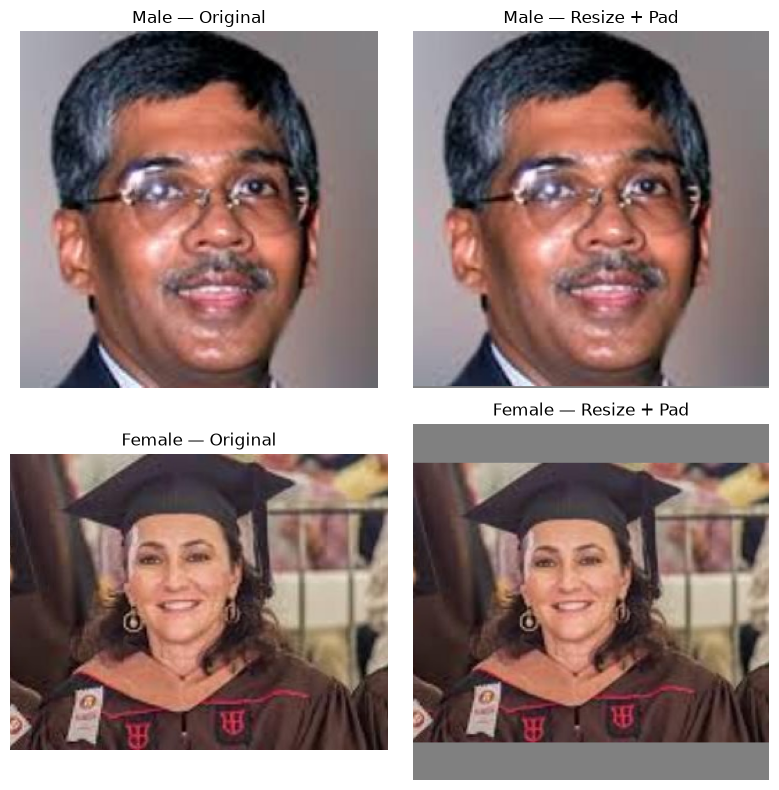

In [5]:
def resizeAndPad(image, size=(64, 64), fill=(128, 128, 128)):
    return ImageOps.pad(
        image,
        (size[1], size[0]),
        method=Image.Resampling.LANCZOS,
        color=fill
    )


classes = ["Male", "Female"]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for i in range(2):
    # Find images belonging to this gender
    classIndices = np.where(y == i)[0]

    # Select a random image from that class
    imgIdx = np.random.choice(classIndices)

    imgPath = os.path.join(rootPath, X[imgIdx])

    with Image.open(imgPath) as source:
        img = source.convert("RGB")
        processedImg = resizeAndPad(img, size=(256, 256))

        print(
            f"{classes[i]}: Original {np.array(img).shape} "
            f"-> Processed {np.array(processedImg).shape}"
        )

        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"{classes[i]} — Original")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(processedImg)
        axes[i, 1].set_title(f"{classes[i]} — Resize + Pad")
        axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
class ResizeAndPad:
    def __init__(self, size=(256, 256), fill=(128, 128, 128)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        height, width = self.size

        return ImageOps.pad(
            image,
            (width, height),  # Pillow expects (width, height)
            method=Image.Resampling.LANCZOS,
            color=self.fill
        )

In [7]:
trainTransform = transforms.Compose([
    ResizeAndPad(size= (256, 256)),
    transforms.RandomRotation(degrees = 5, 
        fill=(128, 128, 128)),
    transforms.RandomAffine(
        degrees=5,
        translate=(0.05, 0.05),
        fill=(128, 128, 128)
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean= [0.5]*3, std= [0.5]*3)
])

valTransform = transforms.Compose([
    ResizeAndPad(size= (256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean= [0.5]*3, std= [0.5]*3)
])

In [8]:
XTrain, XEval, yTrain, yEval = train_test_split(X, y, stratify= y, random_state= 42, test_size = 0.05)
XTrain, XEval, yTrain, yEval 

(array(['23_1_3_20170119164456070.jpg', '56_0_3_20170119180916188.jpg',
        '18_0_3_20170119144144877.jpg', ...,
        '37_0_3_20170119152336983.jpg', '28_1_3_20170119195056772.jpg',
        '27_0_0_20170117134951867.jpg'], shape=(3087,), dtype='<U29'),
 array(['49_0_0_20170117153916924.jpg', '34_0_3_20170119183347270.jpg',
        '36_0_3_20170119183659343.jpg', '70_1_1_20170120223544080.jpg',
        '48_0_3_20170119192924313.jpg', '26_1_3_20170119192405417.jpg',
        '34_0_3_20170119194902451.jpg', '27_0_3_20170119153330881.jpg',
        '20_1_3_20170119180826861.jpg', '26_1_0_20170119192656049.jpg',
        '50_0_3_20170119205151901.jpg', '55_1_3_20170119154458097.jpg',
        '26_0_3_20170119180458307.jpg', '36_1_3_20170119192728122.jpg',
        '25_0_3_20170119171120578.jpg', '37_0_2_20170119193347850.jpg',
        '36_1_3_20170119202208549.jpg', '29_0_3_20170119195112307.jpg',
        '38_1_3_20170119183332565.jpg', '67_0_3_20170119212012082.jpg',
        '36_0_0_2017

In [9]:
class DataSet(Dataset):

    def __init__(self, rootPath, X, y, transform = None):
        self.rootPath = rootPath
        self.X = X
        self.y = y
        self.transform = transform
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, index):
        with Image.open(os.path.join(self.rootPath, self.X[index])) as image:
            img = image.convert("RGB")

        if self.transform is not None:
            img = self.transform(img)
        
        y = torch.tensor(self.y[index].reshape(1), dtype= torch.float32)

        return img, y


In [10]:
train = DataSet(rootPath= rootPath, X= XTrain, y= yTrain, transform= trainTransform)
evalDataset = DataSet(rootPath= rootPath, X= XEval, y= yEval, transform= valTransform)

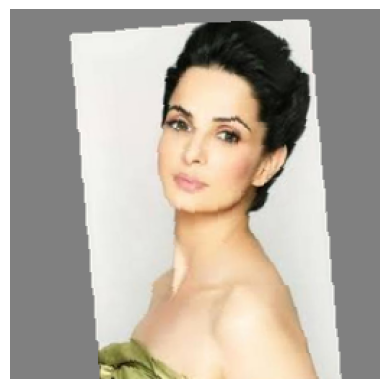

In [11]:
img = train[17][0]

# Reverse normalization: [-1, 1] → [0, 1]
img = img * 0.5 + 0.5

# Convert from (C, H, W) to (H, W, C)
img = img.permute(1, 2, 0).numpy()

plt.imshow(img)
plt.axis("off")
plt.show()

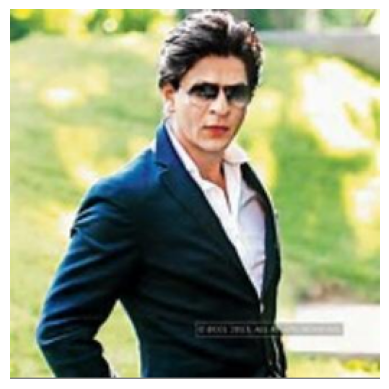

In [12]:
img = evalDataset[17][0]

# Reverse normalization: [-1, 1] → [0, 1]
img = img * 0.5 + 0.5

# Convert from (C, H, W) to (H, W, C)
img = img.permute(1, 2, 0).numpy()

plt.imshow(img)
plt.axis("off")
plt.show()

In [13]:
trainLoader = DataLoader(train, shuffle= True, batch_size= 128, drop_last= False)
evalLoader = DataLoader(evalDataset, shuffle= False, batch_size= len(evalDataset))

In [14]:
torch.manual_seed(42)
torch.set_num_threads(9)

In [15]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()

        self.neuralNet = nn.Sequential(
            nn.Conv2d(in_channels= 3, out_channels= 16, kernel_size= 3, padding= 1, stride= 1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2),

            nn.Conv2d(in_channels= 16, out_channels= 32, kernel_size= 3, padding= 1, stride= 1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2),

            nn.Conv2d(in_channels= 32, out_channels= 64, kernel_size= 3, stride= 1, padding= 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2),

            nn.Conv2d(in_channels= 64, out_channels= 128, kernel_size= 3, stride= 1, padding= 1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2),

            nn.Flatten(),

            nn.Linear(in_features= 16 * 16 * 128, out_features= 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(in_features= 256, out_features= 1),
            nn.Sigmoid(),
        )
    
    def forward(self, X):
        return self.neuralNet(X)

model = Model()
summary(model)

Layer (type:depth-idx)                   Param #
Model                                    --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       448
│    └─BatchNorm2d: 2-2                  32
│    └─ReLU: 2-3                         --
│    └─MaxPool2d: 2-4                    --
│    └─Conv2d: 2-5                       4,640
│    └─BatchNorm2d: 2-6                  64
│    └─ReLU: 2-7                         --
│    └─MaxPool2d: 2-8                    --
│    └─Conv2d: 2-9                       18,496
│    └─BatchNorm2d: 2-10                 128
│    └─ReLU: 2-11                        --
│    └─MaxPool2d: 2-12                   --
│    └─Conv2d: 2-13                      73,856
│    └─BatchNorm2d: 2-14                 256
│    └─ReLU: 2-15                        --
│    └─MaxPool2d: 2-16                   --
│    └─Flatten: 2-17                     --
│    └─Linear: 2-18                      8,388,864
│    └─BatchNorm1d: 2-19                 512
│    

In [16]:
lossFunc = nn.BCELoss()

In [17]:
alpha = 0.0003

optimizer = Adam(params= model.parameters(), lr= alpha)

In [18]:
tLH = []
tAH = []

eLH = []
eAH = []

In [19]:
epochs = 50

bestAccScore = 0

for epoch in range(epochs):

    accAvg = 0
    lossAvg = 0

    model.train()


    for X, y in trainLoader:

        yHat = model(X)
        loss = lossFunc(yHat, y)

        lossAvg += loss.item()
        accAvg += (((yHat > 0.5).int()) == y).float().mean().item()

        optimizer.zero_grad()

        loss.backward()
        optimizer.step()
    
    accAvg /= len(trainLoader)
    lossAvg /= len(trainLoader)

    tLH.append(lossAvg)
    tAH.append(accAvg)

    model.eval()

    acc = 0

    for X, y in evalLoader:

        with torch.no_grad():

            yHat = model(X)
            loss = lossFunc(yHat, y)

            loss= loss.item()
            acc= (((yHat > 0.5).int()) == y).float().mean().item()

            eLH.append(loss)
            eAH.append(acc)
        
        print(f"Epoch {epoch + 1}\nTrain\nLoss:{lossAvg} | acc: {accAvg * 100:.4f}%\n\nValidation\nLoss:{loss} | acc: {acc * 100:.4f}%\n==============================================================")

    if (acc > 0.9):

        if(bestAccScore < acc):

            torch.save(model.state_dict(), "gender_classifier_ai.pth")
            bestAccScore = acc


        

Epoch 1
Train
Loss:0.6649823045730591 | acc: 66.6188%

Validation
Loss:0.6031360030174255 | acc: 69.3252%
Epoch 2
Train
Loss:0.46270259022712706 | acc: 79.1854%

Validation
Loss:0.37988385558128357 | acc: 86.5031%
Epoch 3
Train
Loss:0.3890488004684448 | acc: 82.8583%

Validation
Loss:0.36566299200057983 | acc: 83.4356%
Epoch 4
Train
Loss:0.3470307600498199 | acc: 85.2313%

Validation
Loss:0.3682642877101898 | acc: 85.2761%
Epoch 5
Train
Loss:0.3306226646900177 | acc: 85.7792%

Validation
Loss:0.3367968499660492 | acc: 87.1166%
Epoch 6
Train
Loss:0.32522563755512235 | acc: 86.3708%

Validation
Loss:0.35299262404441833 | acc: 87.1166%
Epoch 7
Train
Loss:0.3083219623565674 | acc: 87.0417%

Validation
Loss:0.35467424988746643 | acc: 87.7301%
Epoch 8
Train
Loss:0.28028308689594267 | acc: 88.9062%

Validation
Loss:0.42400580644607544 | acc: 81.5951%
Epoch 9
Train
Loss:0.24925604999065398 | acc: 90.1396%

Validation
Loss:0.33194923400878906 | acc: 87.1166%
Epoch 10
Train
Loss:0.22818278133869

0.9141104221343994


[]

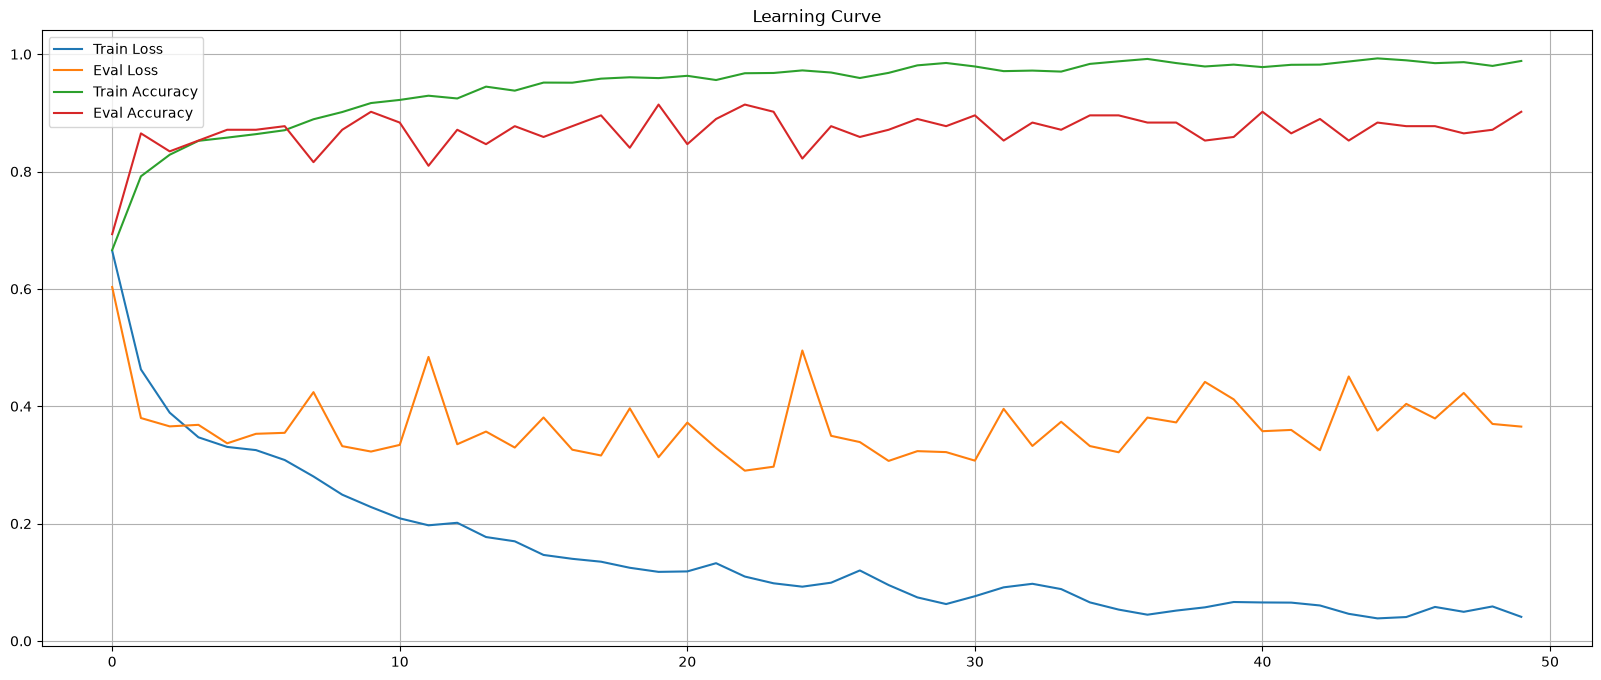

In [20]:
print(bestAccScore)
plt.figure(figsize=(20, 8))
plt.title("Learning Curve")
plt.plot(tLH, label = "Train Loss")
plt.plot(eLH, label = "Eval Loss")
plt.plot(tAH, label = "Train Accuracy")
plt.plot(eAH, label = "Eval Accuracy")
plt.legend(loc = "best")
plt.grid(True)
plt.plot()